# Figure 4. Intermittent rate coding in a spiking ring-attractor network with NMDA currents

The network (`nmdaint/spiking.py`): 2,048 excitatory and 512 inhibitory integrate-and-fire neurons on a ring,
NMDA-only recurrent excitation, a common input that dips and overshoots. Simulating its sessions takes hours
(`scripts/spiking.py`), so the spike counts of 330 "recorded" cells are loaded from `results/spiking/`;
everything after that (decoding, On/Off states, tuning, population geometry) runs here, in about 5 minutes,
with the same methods as the recordings: `nmdaint/spiking_readout.py`, `nmdaint/population.py`.
The recordings' side of d and e comes from `scripts/recordings.py`.

In [1]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import ttest_1samp, ttest_rel
from nmdaint import onoff, paths, population, spiking, spiking_readout as SR
from plots import fig4, style

load = lambda name: dict(np.load(paths.results('spiking', 'sessions', name + '.npz')))

## Parameters

In [2]:
LENGTH_SESSIONS = range(4)        # b: sessions behind the state-length distributions (12 available)
TUNING_SESSION, N_SPLITS = 0, 10  # c: session and random cell splits
POP_SESSIONS = range(10)          # d, e: sessions (12 available); d shows the first
WINDOWS = dict(delay=(500, 1400), pre=(-400, -50))   # d, e: window centres of delay and pre-cue activity (ms)
QUIET = 1000                      # a: the long trials' delay without dips, as simulated (scripts/spiking.py)

## a. A long trial
1 s of delay with a constant common input, then 1 s with dips. All-units decoder trained on the 480-trial session
(correct trials), leave-one-out, against 30 label shuffles.

In [3]:
d = load('long_session')
X, tz = SR.windows(d['counts'][d['held']], d['t10'], -300, np.inf)
z, states = SR.states(X, d['cue'][d['held']], np.random.default_rng(0), np.where(X.sum((0, 1)) > 0)[0], tz, valid=tz >= 0)
ras = np.load(paths.results('spiking', 'example_raster.npz'))
k = int(np.flatnonzero(np.flatnonzero(d['held']) == ras['trial'])[0])      # the example among the correct trials
example = dict(spike_t=ras['spike_t'], spike_cell=ras['spike_cell'], t1=ras['t1'], m_eff=ras['m_eff'], tz=tz, z=z[k],
               state=states[k], quiet=QUIET, cue_dur=spiking.P['cue_dur'], n_e=spiking.P['N_E'])
print(f"memory held in {d['held'].mean():.0%} of the long trials")

memory held in 94% of the long trials


The example trial's z (On red, Off blue) and the mean over trials; and the spikes behind it.

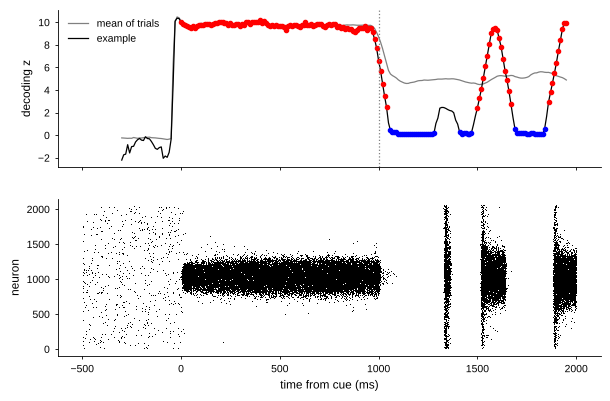

In [4]:
_, ax = plt.subplots(2, 1, figsize=(7, 4.5), sharex=True)
ax[0].plot(tz, z.mean(0), color='grey', label='mean of trials'); ax[0].plot(tz, z[k], 'k', label='example')
for lab, col in ((1, 'r'), (-1, 'b')):
    ax[0].plot(tz[states[k] == lab], z[k][states[k] == lab], '.', color=col)
ax[0].axvline(QUIET, color='grey', ls=':'); ax[0].set_ylabel('decoding z'); ax[0].legend()
ax[1].plot(ras['spike_t'], ras['spike_cell'], ',k'); ax[1].set_ylabel('neuron'); ax[1].set_xlabel('time from cue (ms)');

## b. On and Off state lengths of the all-units decoder

In [5]:
reads = [SR.read_session(load(f'session_{s}'), seed=s) for s in LENGTH_SESSIONS]
lengths = {**{f'h_{st}': np.sum([r[f'h_{st}'] for r in reads], 0) for st in ('on', 'off')},
           **{f'n_{st}': np.mean([r[f'n_{st}'] for r in reads]) for st in ('on', 'off')}}
pd.DataFrame([{k: r[k] for k in ('n_off', 'off_median', 'frac_off', 'n_on', 'on_median', 'frac_on', 'mu_on')} for r in reads],
             index=list(LENGTH_SESSIONS)).round(2)

,n_off,off_median,frac_off,n_on,on_median,frac_on,mu_on
0,3.05,100.0,0.26,3.40,200.0,0.58,5.76
1,3.06,100.0,0.26,3.30,200.0,0.58,5.43
2,2.93,100.0,0.25,3.52,200.0,0.60,6.01
3,2.90,90.0,0.23,3.54,200.0,0.61,5.84


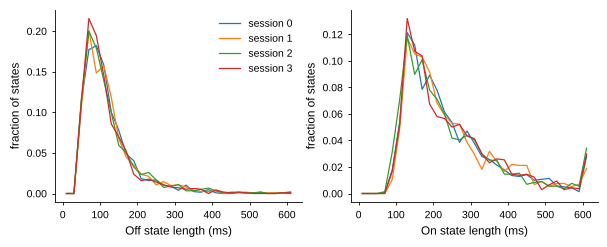

In [6]:
_, ax = plt.subplots(1, 2, figsize=(7, 2.5))
for s, rd in zip(LENGTH_SESSIONS, reads):
    for a, st in zip(ax, ('off', 'on')):
        a.plot(20 * np.arange(31) + 10, rd['h_' + st] / rd['h_' + st].sum(), label=f'session {s}')
for a, st in zip(ax, ('Off', 'On')):
    a.set_xlabel(f'{st} state length (ms)'); a.set_ylabel('fraction of states')
ax[0].legend();

## Play: how many decoded cells?
In the recordings, fewer cells give more Off states (Fig. 2). In the network (session 0) the number barely
matters: its cells are strongly tuned and the Off states are true silences, not decoder noise.

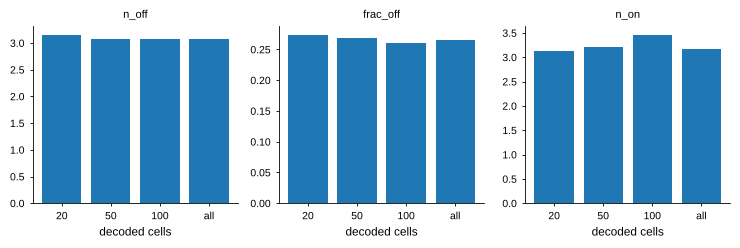

In [7]:
dd = load('session_0')
Xs, tzs = SR.windows(dd['counts'][dd['held']], dd['t10'])
rng = np.random.default_rng(0)
cells = {n: rng.choice(Xs.shape[2], n, replace=False) for n in (20, 50, 100)}
cells['all'] = np.where(Xs.sum((0, 1)) > 0)[0]
few = {n: onoff.stats(SR.states(Xs, dd['cue'][dd['held']], rng, u, tzs)[1], (tzs >= 500) & (tzs <= 1400)) for n, u in cells.items()}
_, ax = plt.subplots(1, 3, figsize=(9, 2.3))
for a, key in zip(ax, ('n_off', 'frac_off', 'n_on')):
    a.bar([str(n) for n in few], [f[key] for f in few.values()]); a.set_title(key); a.set_xlabel('decoded cells')

## c. Tuning of held-out cells in On and Off states
Cells split in halves at random; On/Off from the decoder of one half; the other half's z-scored rates averaged
per cue in On and in Off time points, aligned to each cell's preferred cue, minus the same with shuffled cues.

In [8]:
d = load(f'session_{TUNING_SESSION}')
X, tz = SR.windows(d['counts'][d['held']], d['t10'])
tuning = SR.tuning(X, tz, d['cue'][d['held']], np.random.default_rng(0), n_rep=N_SPLITS)
print(f"preferred cue: On {tuning['on'][:, 0].mean():.2f} z, Off {tuning['off'][:, 0].mean():.2f} z; "
      f"opposite: On {tuning['on'][:, 4].mean():.2f}, Off {tuning['off'][:, 4].mean():.2f}")

preferred cue: On 1.26 z, Off 0.02 z; opposite: On -0.58, Off -0.01


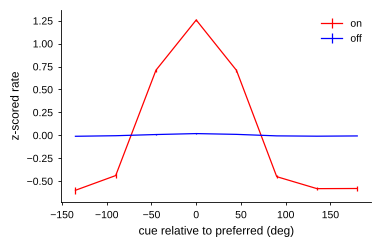

In [9]:
plt.figure(figsize=(4, 2.5))
for st, col in (('on', 'r'), ('off', 'b')):
    plt.errorbar(45 * np.arange(-3, 5), np.roll(tuning[st].mean(0), 3), tuning[st].std(0) / np.sqrt(len(tuning[st])),
                 color=col, label=st)
plt.xlabel('cue relative to preferred (deg)'); plt.ylabel('z-scored rate'); plt.legend();

## d, e. Population geometry in On and Off states
On/Off from all cells of one random half; the other half's activity in the plane of the cue means (d) and its
Procrustes similarity to the ring of cue means (e; 0 = chance, 1 = identical shape).

In [10]:
rows, plane = [], None
for s in POP_SESSIONS:
    d = load(f'session_{s}')
    c, cue = d['counts'][d['held']], d['cue'][d['held']]
    X, tz = SR.windows(c, d['t10'])
    Xpre, _ = SR.windows(c, d['t10'], *WINDOWS['pre'])
    H1, H2 = population.unit_halves(X.shape[2])
    _, st = SR.states(X, cue, np.random.default_rng(s + 1), H1, tz)
    dl = (tz >= WINDOWS['delay'][0]) & (tz <= WINDOWS['delay'][1])
    r, pl = population.analyse(SR.zscore(X)[:, dl][:, :, H2], SR.zscore(Xpre)[:, :, H2], cue, st[:, dl], plane=plane is None)
    rows += [dict(session=s, **x) for x in r]
    plane = pl if plane is None else plane
procrustes = {'network': pd.DataFrame(rows), 'data': pd.read_csv(paths.results('recordings', 'procrustes.csv'))}
planes = {'network': pd.DataFrame(plane).assign(angle_deg=45 * np.arange(8)),
          'data': pd.read_csv(paths.results('recordings', 'pca_plane.csv'))}
for name, D in procrustes.items():
    N = D[D.space == 'pcs'].pivot(index='session', columns='period', values='normalised')
    print(f"{name}: On {N.on.mean():.2f}, Off {N.off.mean():.2f} (vs 0: p = {ttest_1samp(N.off, 0, nan_policy='omit').pvalue:.1e}),"
          f" pre-cue {N.pre.mean():.2f}; Off vs pre-cue p = {ttest_rel(N.off, N.pre, nan_policy='omit').pvalue:.1e}; {len(N)} sessions")

network: On 0.99, Off 0.84 (vs 0: p = 3.4e-11), pre-cue -0.01; Off vs pre-cue p = 8.8e-07; 10 sessions
data: On 0.49, Off 0.42 (vs 0: p = 1.8e-10), pre-cue 0.01; Off vs pre-cue p = 2.3e-08; 25 sessions


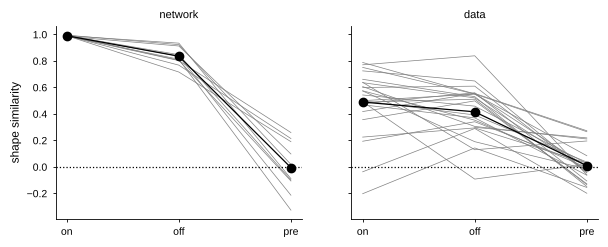

In [11]:
_, ax = plt.subplots(1, 2, figsize=(7, 2.5), sharey=True)
for a, (name, D) in zip(ax, procrustes.items()):
    N = D[D.space == 'pcs'].pivot(index='session', columns='period', values='normalised')[['on', 'off', 'pre']]
    a.plot(N.values.T, color='grey', lw=0.5); a.plot(N.mean().values, 'k-o')
    a.set_xticks(range(3), N.columns); a.set_title(name); a.axhline(0, color='k', ls=':')
ax[0].set_ylabel('shape similarity');

## Figure

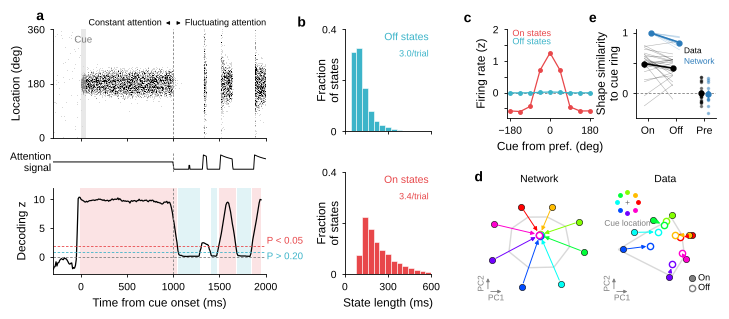

In [12]:
fig = fig4.draw(example, lengths, tuning, planes, procrustes)
style.save(fig, '../figures/fig4.png')